In [1]:
from tensorflow import lite
import tensorflow as tf
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')
tf.config.optimizer.set_jit(True)
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd
import random, os
import shutil
import matplotlib.pyplot as plt
from matplotlib.image import imread
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.metrics import categorical_accuracy
from sklearn.model_selection import train_test_split

## Download Dataset from Kaggle

To download a dataset from Kaggle, you need a Kaggle API key.

1. Go to your Kaggle account (kaggle.com/your-username/account).
2. Under the 'API' section, click 'Create New API Token'. This will download a `kaggle.json` file.
3. Open this `kaggle.json` file. It contains your username and key.
4. In Colab, click on the 🔑 icon (Secrets) in the left sidebar.
5. Add two new secrets:
   - Name: `KAGGLE_USERNAME`, Value: (your Kaggle username from `kaggle.json`)
   - Name: `KAGGLE_KEY`, Value: (your Kaggle API key from `kaggle.json`)

In [2]:
# Install the Kaggle library
!pip install kaggle

### Manual Dataset Upload Steps (since Kaggle API authentication failed)

Since the Kaggle API could not authenticate without a username, you must manually upload the dataset files. Follow these steps:

1.  **Run the cell below to create the target directory.**
2.  **Go to the 'Files' tab** (folder icon on the left sidebar).
3.  **Upload `train.csv`** into the `diabetic-retinopathy-224x224-gaussian-filtered` directory.
4.  **Upload the `gaussian_filtered_images` folder** into the `diabetic-retinopathy-224x224-gaussian-filtered` directory. If you upload it as a `.zip` file, you'll need to add another code cell to unzip it into the correct location (e.g., `!unzip ./diabetic-retinopathy-224x224-gaussian-filtered/your_images.zip -d ./diabetic-retinopathy-224x224-gaussian-filtered/`).

In [3]:
!pip install -q kaggle

In [4]:
from google.colab import files
files.upload()

Saving kaggle (2).json to kaggle (2).json


{'kaggle (2).json': b'{"username":"tanib1409","key":"e233685b658f5f792a36dbe64654a23d"}'}

In [5]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [6]:
!kaggle competitions list

You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication


In [7]:
!kaggle datasets download -d sovitrath/diabetic-retinopathy-224x224-gaussian-filtered

Dataset URL: https://www.kaggle.com/datasets/sovitrath/diabetic-retinopathy-224x224-gaussian-filtered
License(s): CC0-1.0
100% 427M/427M [00:02<00:00, 178MB/s]



In [8]:
!unzip -q diabetic-retinopathy-224x224-gaussian-filtered.zip -d diabetic-retinopathy-224x224-gaussian-filtered

In [9]:
!ls diabetic-retinopathy-224x224-gaussian-filtered

gaussian_filtered_images  train.csv


In [10]:
import pandas as pd

df = pd.read_csv('./diabetic-retinopathy-224x224-gaussian-filtered/train.csv')

diagnosis_dict_binary = {
    0: 'No_DR',
    1: 'DR',
    2: 'DR',
    3: 'DR',
    4: 'DR'
}

diagnosis_dict = {
    0: 'No_DR',
    1: 'Mild',
    2: 'Moderate',
    3: 'Severe',
    4: 'Proliferate_DR',
}


df['binary_type'] =  df['diagnosis'].map(diagnosis_dict_binary.get)
df['type'] = df['diagnosis'].map(diagnosis_dict.get)
df.head()

,id_code,diagnosis,binary_type,type
0,000c1434d8d7,2,DR,Moderate
1,001639a390f0,4,DR,Proliferate_DR
2,0024cdab0c1e,1,DR,Mild
3,002c21358ce6,0,No_DR,No_DR
4,005b95c28852,0,No_DR,No_DR


<Axes: ylabel='type'>

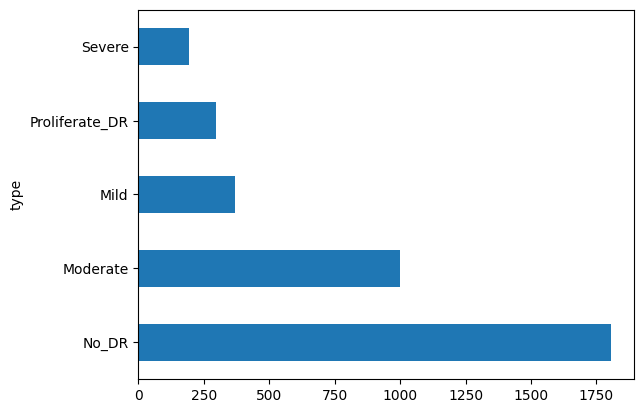

In [11]:
df['type'].value_counts().plot(kind='barh')

In [12]:
train_intermediate, val = train_test_split(df, test_size = 0.15, stratify = df['type'])
train, test = train_test_split(train_intermediate, test_size = 0.15 / (1 - 0.15), stratify = train_intermediate['type'])

print("For Training Dataset :")
print(train['type'].value_counts(), '\n')
print("For Testing Dataset :")
print(test['type'].value_counts(), '\n')
print("For Validation Dataset :")
print(val['type'].value_counts(), '\n')

For Training Dataset :
type
No_DR             1263
Moderate           699
Mild               258
Proliferate_DR     207
Severe             135
Name: count, dtype: int64 

For Testing Dataset :
type
No_DR             271
Moderate          150
Mild               56
Proliferate_DR     44
Severe             29
Name: count, dtype: int64 

For Validation Dataset :
type
No_DR             271
Moderate          150
Mild               56
Proliferate_DR     44
Severe             29
Name: count, dtype: int64 



In [13]:
base_dir = ''

train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

if os.path.exists(base_dir):
    shutil.rmtree(base_dir)

if os.path.exists(train_dir):
    shutil.rmtree(train_dir)
os.makedirs(train_dir)

if os.path.exists(val_dir):
    shutil.rmtree(val_dir)
os.makedirs(val_dir)

if os.path.exists(test_dir):
    shutil.rmtree(test_dir)
os.makedirs(test_dir)

In [14]:
src_dir = r'diabetic-retinopathy-224x224-gaussian-filtered/gaussian_filtered_images/gaussian_filtered_images'
for index, row in train.iterrows():
    diagnosis = row['type']
    binary_diagnosis = row['binary_type']
    id_code = row['id_code'] + ".png"
    srcfile = os.path.join(src_dir, diagnosis, id_code)
    dstfile = os.path.join(train_dir, binary_diagnosis)
    os.makedirs(dstfile, exist_ok = True)
    shutil.copy(srcfile, dstfile)

for index, row in val.iterrows():
    diagnosis = row['type']
    binary_diagnosis = row['binary_type']
    id_code = row['id_code'] + ".png"
    srcfile = os.path.join(src_dir, diagnosis, id_code)
    dstfile = os.path.join(val_dir, binary_diagnosis)
    os.makedirs(dstfile, exist_ok = True)
    shutil.copy(srcfile, dstfile)

for index, row in test.iterrows():
    diagnosis = row['type']
    binary_diagnosis = row['binary_type']
    id_code = row['id_code'] + ".png"
    srcfile = os.path.join(src_dir, diagnosis, id_code)
    dstfile = os.path.join(test_dir, binary_diagnosis)
    os.makedirs(dstfile, exist_ok = True)
    shutil.copy(srcfile, dstfile)

In [22]:
import tensorflow as tf

AUTOTUNE = tf.data.AUTOTUNE

# Load datasets with one-hot encoded targets
train_batches = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical',
    shuffle=True
)

val_batches = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical',
    shuffle=True
)

test_batches = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical',
    shuffle=False
)

# Rescale pixel values from [0, 255] to [0, 1]
rescale = tf.keras.layers.Rescaling(1./255)
train_batches = train_batches.map(lambda x, y: (rescale(x), y), num_parallel_calls=AUTOTUNE)
val_batches = val_batches.map(lambda x, y: (rescale(x), y), num_parallel_calls=AUTOTUNE)
test_batches = test_batches.map(lambda x, y: (rescale(x), y), num_parallel_calls=AUTOTUNE)

# Apply performance optimization (caching & prefetching)
train_batches = train_batches.cache().prefetch(buffer_size=AUTOTUNE)
val_batches = val_batches.cache().prefetch(buffer_size=AUTOTUNE)
test_batches = test_batches.cache().prefetch(buffer_size=AUTOTUNE)

Found 2562 files belonging to 2 classes.
Found 550 files belonging to 2 classes.
Found 550 files belonging to 2 classes.


In [23]:
# 1. Define Model Architecture (Keras 3+ explicit Input + Mixed Precision float32 output)
model = tf.keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(16, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),

    # Softmax output set explicitly to float32 for mixed-precision numerical safety
    layers.Dense(2, activation='softmax', dtype='float32')
])

# 2. Compile Model with XLA JIT Compilation enabled
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'],
    jit_compile=True
)

# 3. Train Model with prefetched tf.data batches
history = model.fit(
    train_batches,
    epochs=15,
    validation_data=val_batches
)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 30s 201ms/step - accuracy: 0.8306 - loss: 0.4701 - val_accuracy: 0.9055 - val_loss: 0.2399
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9094 - loss: 0.2238 - val_accuracy: 0.8855 - val_loss: 0.2835
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9208 - loss: 0.2065 - val_accuracy: 0.9127 - val_loss: 0.2336
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9286 - loss: 0.1885 - val_accuracy: 0.9255 - val_loss: 0.2252
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9317 - loss: 0.1812 - val_accuracy: 0.9255 - val_loss: 0.2368
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9457 - loss: 0.1592 - val_accuracy: 0.9182 - val_loss: 0.2318
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9481 - loss: 0.1500 - val_accuracy: 0.9236 - val_loss: 0.2413
Epoch 8/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9485 - loss: 0.1420 - val_accuracy: 0.9218 -

In [36]:
import time

# 1. Start the timer
start_time = time.time()

# 2. Train the model
history = model.fit(
    train_batches,
    epochs=15,
    validation_data=val_batches
)

# 3. Stop the timer and calculate duration
end_time = time.time()
total_seconds = end_time - start_time

# 4. Print total training time
print(f"\n==========================================")
print(f"Total Training Time: {total_seconds:.2f} seconds ({total_seconds / 60:.2f} minutes)")
print(f"==========================================")

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9738 - loss: 0.0781 - val_accuracy: 0.9291 - val_loss: 0.4022
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9785 - loss: 0.0600 - val_accuracy: 0.9273 - val_loss: 0.4928
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9824 - loss: 0.0447 - val_accuracy: 0.9291 - val_loss: 0.5934
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9887 - loss: 0.0366 - val_accuracy: 0.9309 - val_loss: 0.5623
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9887 - loss: 0.0306 - val_accuracy: 0.9309 - val_loss: 0.5702
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9922 - loss: 0.0204 - val_accuracy: 0.9291 - val_loss: 0.5642
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9922 - loss: 0.0195 - val_accuracy: 0.9236 - val_loss: 0.5964
Epoch 8/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9922 - loss: 0.0198 - val_accuracy: 0.9236 - v

In [46]:
model.save('64x3-CNN.keras')

In [45]:
loss, acc = model.evaluate(test_batches, verbose=1)
print("Loss: ", loss)
print("Accuracy: ", acc)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9291 - loss: 0.4950
Loss:  0.49496138095855713
Accuracy:  0.9290909171104431


In [39]:
import tensorflow as tf
import cv2
import numpy as np
import matplotlib.pyplot as plt


def predict_class(path):
    img = cv2.imread(path)

    RGBImg = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
    RGBImg= cv2.resize(RGBImg,(224,224))
    plt.imshow(RGBImg)
    image = np.array(RGBImg) / 255.0
    new_model = tf.keras.models.load_model("64x3-CNN.keras")
    predict=new_model.predict(np.array([image]))
    per=np.argmax(predict,axis=1)
    if per==1:
        print('Diabetic Retinopathy Not Detected')
    else:
        print('Diabetic Retinopathy Detected')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 644ms/step
Diabetic Retinopathy Detected


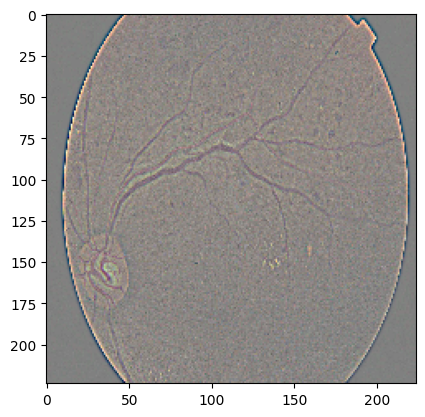

In [40]:
predict_class('diabetic-retinopathy-224x224-gaussian-filtered/gaussian_filtered_images/gaussian_filtered_images/Severe/1b495ac025b7.png')

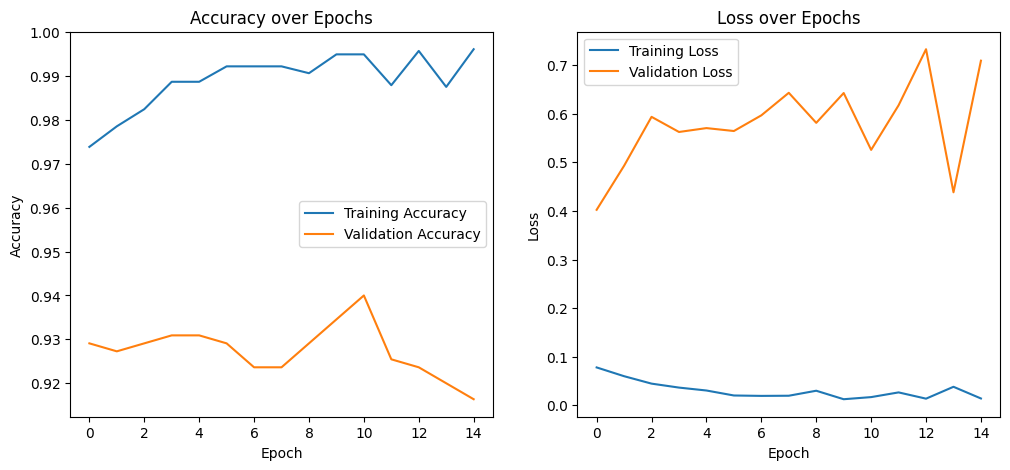

In [41]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.show()

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


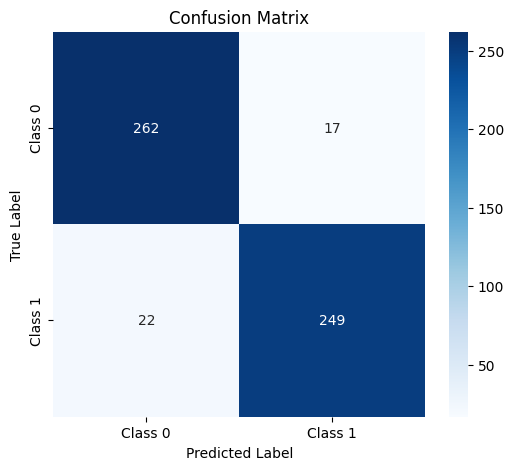

In [42]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 1. Get true labels from the test dataset
true_labels = np.concatenate([y for x, y in test_batches], axis=0)
if len(true_labels.shape) > 1 and true_labels.shape[1] > 1:
    true_labels = np.argmax(true_labels, axis=1)

# 2. Get predicted labels from the trained model
predictions = model.predict(test_batches)
predicted_labels = np.argmax(predictions, axis=1)

# 3. Retrieve class names dynamically
if hasattr(test_batches, 'class_names'):
    class_names = test_batches.class_names
else:
    class_names = ['Class 0', 'Class 1']

# 4. Generate and display Confusion Matrix
cm = confusion_matrix(true_labels, predicted_labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

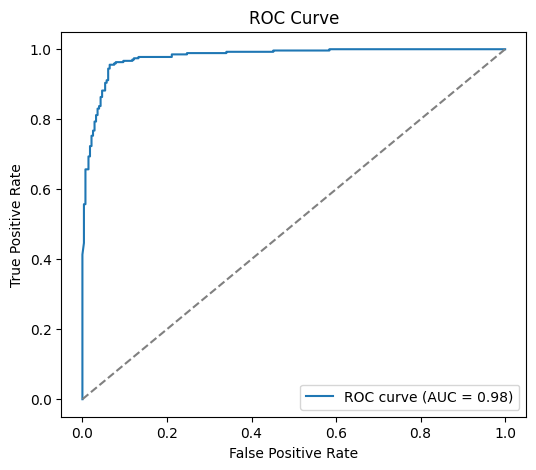

In [43]:
from sklearn.metrics import roc_curve, auc

# Get the probability of the positive class ('No_DR' or 'DR' — check class_names order)
positive_class_index = 1  # adjust if needed based on class_names order
fpr, tpr, _ = roc_curve(true_labels, predictions[:, positive_class_index])
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0,1], [0,1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [44]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Get true labels by iterating through the tf.data dataset batches
true_labels = np.concatenate([y for x, y in test_batches], axis=0)

# If one-hot encoded, convert targets to class indices
if len(true_labels.shape) > 1 and true_labels.shape[1] > 1:
    true_labels = np.argmax(true_labels, axis=1)

# 2. Get model predictions
predictions = model.predict(test_batches, verbose=1)
predicted_labels = np.argmax(predictions, axis=1)

# 3. Retrieve class names safely
if hasattr(test_batches, 'class_names'):
    class_names = test_batches.class_names
else:
    class_names = ['Class 0', 'Class 1']

# 4. Print metrics
print("Accuracy:", accuracy_score(true_labels, predicted_labels))
print("\nClassification Report:\n")
print(classification_report(true_labels, predicted_labels, target_names=class_names))
print("Confusion Matrix:\n")
print(confusion_matrix(true_labels, predicted_labels))

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Accuracy: 0.9290909090909091

Classification Report:

              precision    recall  f1-score   support

     Class 0       0.92      0.94      0.93       279
     Class 1       0.94      0.92      0.93       271

    accuracy                           0.93       550
   macro avg       0.93      0.93      0.93       550
weighted avg       0.93      0.93      0.93       550

Confusion Matrix:

[[262  17]
 [ 22 249]]


In [35]:
import time

# Start timer
start_time = time.time()

# Evaluate on test set
loss, acc = model.evaluate(test_batches, verbose=1)

# End timer
end_time = time.time()
total_seconds = end_time - start_time

print(f"Test Accuracy: {acc:.4f}")
print(f"Test Loss: {loss:.4f}")
print(f"Evaluation Time: {total_seconds:.2f} seconds")

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9327 - loss: 0.3615
Test Accuracy: 0.9327
Test Loss: 0.3615
Evaluation Time: 0.24 seconds
